In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

1.	Загрузи данные из CSV файла в pd.DataFrame.

In [18]:
df = pd.read_csv('../data/loan.csv')

C:\Users\DENIS\AppData\Local\Temp\ipykernel_20400\4068791134.py:1: DtypeWarning: Columns (19: desc, 55: verification_status_joint) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/loan.csv')


2.	Определи доли для различных групп заявок (группа лежит в поле application_type)

In [19]:
group_sizes = df['application_type'].value_counts()
group_shares = group_sizes / len(df)
print('Размеры групп:\n', group_sizes)
print('Доли групп:\n', group_shares)

Размеры групп:
 application_type
INDIVIDUAL    886868
JOINT            511
Name: count, dtype: int64
Доли групп:
 application_type
INDIVIDUAL    0.999424
JOINT         0.000576
Name: count, dtype: float64


3.	Проанализируй количество пустых значений для каждой из групп заявок:

o	Проанализируй общее количество записей в группах: удали из выборки записи той группы, чья доля меньше 5% от общего количества записей.

o	Проанализируй заполняемость полей: удали поля, у которых доля пустых значений на всей выборке превышает 20%.


In [20]:
small_groups = group_shares[group_shares < 0.05].index
print('Удаляемые группы:', list(small_groups))
df = df[~df['application_type'].isin(small_groups)].copy()

Удаляемые группы: ['JOINT']


In [21]:
missing_share = df.isnull().mean()
print('Доля пустых значений по полям:\n', missing_share.sort_values(ascending=False)*100)

Доля пустых значений по полям:
 annual_inc_joint             100.000000
verification_status_joint    100.000000
dti_joint                    100.000000
il_util                       97.916714
mths_since_rcnt_il            97.671807
                                ...    
application_type               0.000000
collection_recovery_fee        0.000000
recoveries                     0.000000
total_rec_late_fee             0.000000
last_pymnt_amnt                0.000000
Length: 74, dtype: float64


In [22]:
cols_to_drop = missing_share[missing_share > 0.2].index
print('Удаляемые поля:', list(cols_to_drop))
df = df.drop(columns=cols_to_drop)

Удаляемые поля: ['desc', 'mths_since_last_delinq', 'mths_since_last_record', 'next_pymnt_d', 'mths_since_last_major_derog', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m']


In [23]:
print('Итоговый размер выборки:', df.shape)

Итоговый размер выборки: (886868, 52)


4.	Проанализируй количество дубликатов в оставшихся полях:

o	Укажи, как часто встречается уникальное значение в поле для ‘grade’, ‘home_ownership’, ‘verification_status’, ‘pymnt_plan’.

o	Проанализируй оставшиеся столбцы. Удали поля, у которых количество уникальных значений меньше 10 и распределение значений сильно смещено (доля одного значения от общего числа составляет >80%).


In [27]:
cat_cols = ['grade', 'home_ownership', 'verification_status', 'pymnt_plan']

for col in cat_cols:
    print(f'\n=== {col} ===')
    freq = df[col].value_counts(dropna=False)
    share = df[col].value_counts(normalize=True, dropna=False).mul(100).round(2)
    summary = pd.concat([freq, share], axis=1)
    summary.columns = ['count', 'share_%']
    print(summary)


=== grade ===
        count  share_%
grade                 
B      254433    28.69
C      245717    27.71
A      148184    16.71
D      139419    15.72
E       70614     7.96
F       23022     2.60
G        5479     0.62

=== home_ownership ===
                 count  share_%
home_ownership                 
MORTGAGE        443203    49.97
RENT            355995    40.14
OWN              87435     9.86
OTHER              182     0.02
NONE                50     0.01
ANY                  3     0.00

=== verification_status ===
                      count  share_%
verification_status                 
Source Verified      329424    37.14
Verified             290810    32.79
Not Verified         266634    30.06

=== pymnt_plan ===
             count  share_%
pymnt_plan                 
n           886858    100.0
y               10      0.0


In [29]:
n_rows = len(df)
cols_to_drop = []

for col in df.columns:
    n_unique = df[col].nunique(dropna=True)            # число уникальных значений
    if n_unique < 10:
        top_share = df[col].value_counts(normalize=True, dropna=True).iloc[0]  # доля самого частого значения
        if top_share > 0.80:
            cols_to_drop.append((col, n_unique, round(top_share * 100, 2)))

print('\nКандидаты на удаление (уникальных < 10 и доля доминирующего значения > 80%):')
for col, nu, ts in cols_to_drop:
    print(f'  {col}: {nu} уникальных, доминирующее значение — {ts}%')


Кандидаты на удаление (уникальных < 10 и доля доминирующего значения > 80%):
  pymnt_plan: 2 уникальных, доминирующее значение — 100.0%
  policy_code: 1 уникальных, доминирующее значение — 100.0%
  application_type: 1 уникальных, доминирующее значение — 100.0%
  acc_now_delinq: 8 уникальных, доминирующее значение — 99.54%


In [ ]:
df = df.drop(columns=[c[0] for c in cols_to_drop])
print('\nИтоговый размер выборки:', df.shape)


Итоговый размер выборки: (886868, 48)


5.	Проанализируй числовые поля:

o	Построй  графики распределения значений (histplot) для 'loan_amnt', 'funded_amnt', 'int_rate', 'installment', 'sub_grade', 'home_ownership';

o	Приведи основную статистику для поля ‘loan_amnt’. Укажи:

▪	Максимальное и минимальное значения.

▪	Среднее значение.

▪	Медианное значение.

▪	Стандартное отклонение.

▪	Квантили уровня 1%, 5%, 95%, 99%.

o	Сделай вывод на основании полученных статистик.
Например: низкое значение стандартного отклонения по сравнению со средним указывает на однородность сумм займов, а высокие или низкие квантили (1%, 5%, 95%, 99%) укажут на возможные экстремальные значения и выбросы.

o	Построй boxplot для полей ‘loan_amnt’, ‘installment’, ‘int_rate’. Визуально оцени, как распределены значения сумм кредита, ежемесячных платежей и процентных ставок у заёмщиков. Присутствуют ли значимые экстремальные значения и выбросы?

o	Оцени распределение числовых переменных относительно статуса займа (‘loan_status’). Построй графики boxplot для следующих полей:

▪	‘int_rate’.

▪	‘dti’.

▪	‘Loan_amnt’.

Оцени, как эти показатели варьируются относительно разных статусов займов (например, выплаченные, дефолтные, просроченные и т. д.). Попытайся выявить тенденции (например, более высокие процентные ставки у дефолтных займов могут свидетельствовать о большем риске; отношение долга к доходу (dti) можно использовать для оценки уровня закредитованности клиентов, что также может коррелировать со статусом займа).
Построй график barplot для среднего значения ‘annual_inc’ по ‘loan_status’. Сделай вывод о форме распределения дохода заёмщика относительно статуса по его кредиту.

o	Оцени  корреляцию между полями ['int_rate', 'loan_amnt', 'total_pymnt', 'total_acc'].
Построй корреляционную матрицу (.corr()).
Укажи пару полей с наибольшим значением корреляции.
Построй график, описывающий взаимосвязь между этой парой полей. 


In [33]:
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

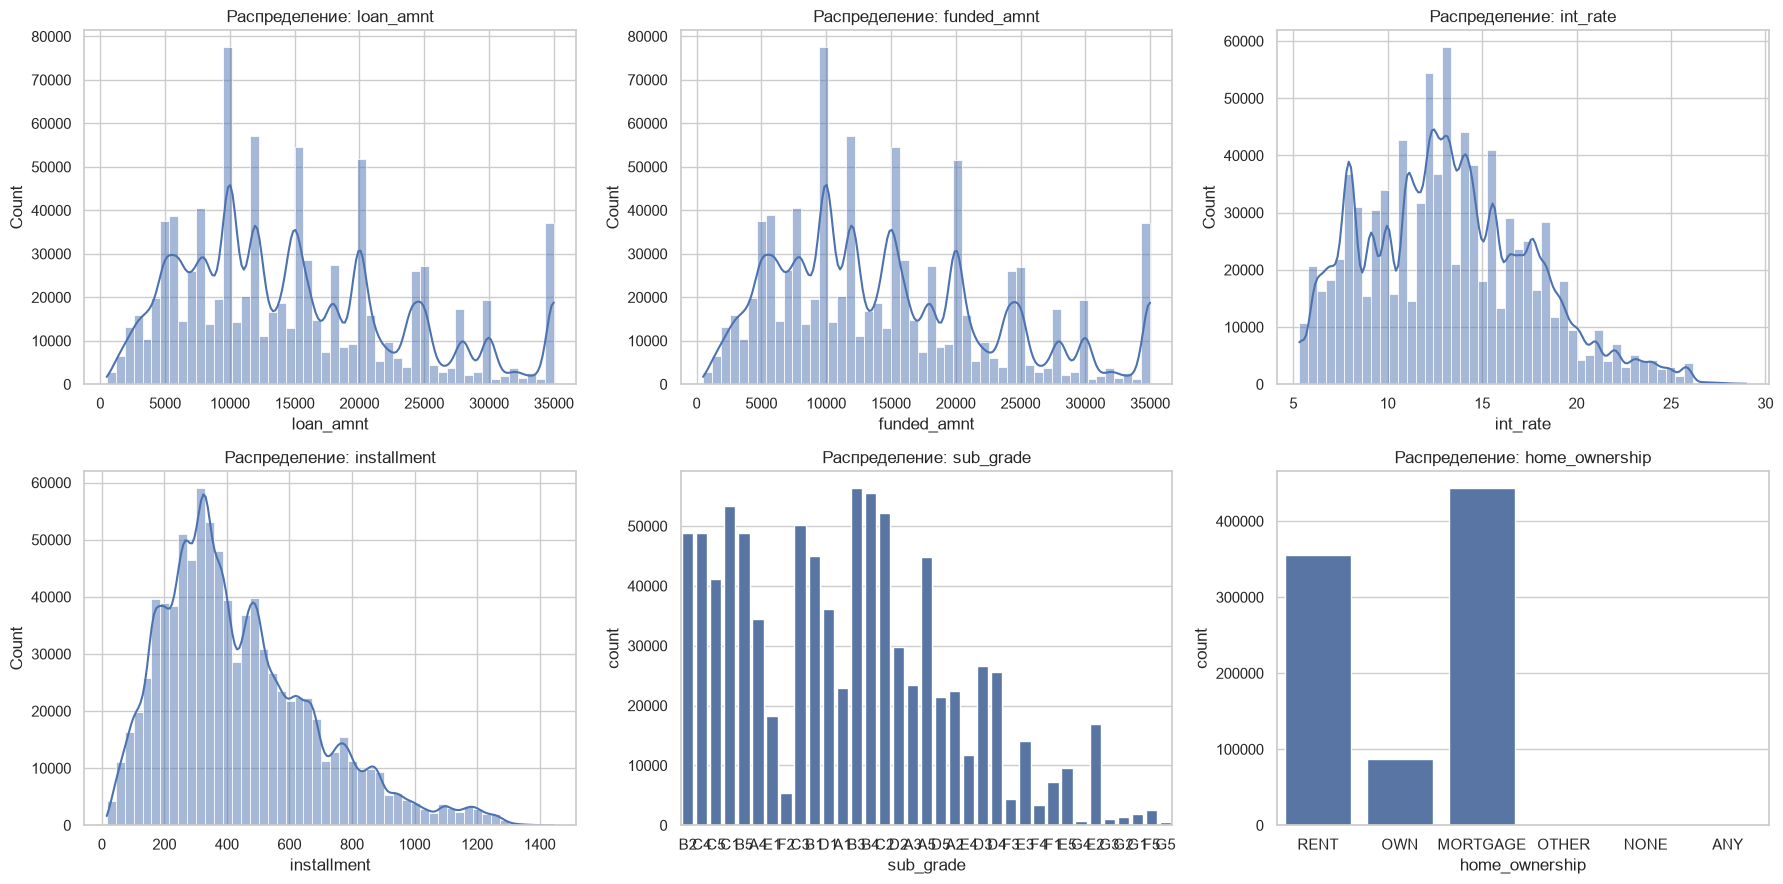

In [34]:
num_cols = ['loan_amnt', 'funded_amnt', 'int_rate', 'installment']
cat_cols = ['sub_grade', 'home_ownership']

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, num_cols + cat_cols):
    if col in num_cols:
        sns.histplot(df[col].dropna(), bins=50, kde=True, ax=ax)
    else:
        sns.countplot(data=df, x=col, ax=ax)          # для категорий так нагляднее
    ax.set_title(f'Распределение: {col}')
plt.tight_layout()
plt.savefig('distributions.png', dpi=150)
plt.show()

In [35]:
s = df['loan_amnt'].dropna()
print('min:', s.min())
print('max:', s.max())
print('mean:', round(s.mean(), 2))
print('median:', s.median())
print('std:', round(s.std(), 2))
print('квантили 1/5/95/99%:')
print(s.quantile([0.01, 0.05, 0.95, 0.99]))

min: 500.0
max: 35000.0
mean: 14752.59
median: 13000.0
std: 8434.36
квантили 1/5/95/99%:
0.01     1800.0
0.05     3600.0
0.95    32000.0
0.99    35000.0
Name: loan_amnt, dtype: float64


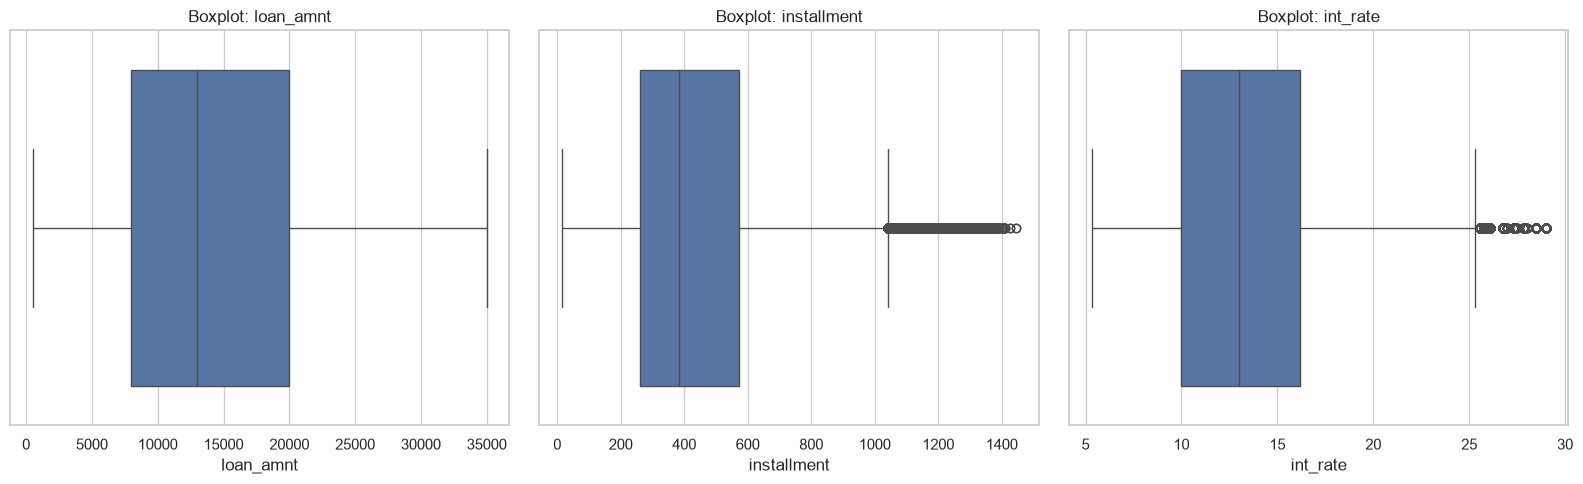

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ['loan_amnt', 'installment', 'int_rate']):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f'Boxplot: {col}')
plt.tight_layout()
plt.savefig('boxplots.png', dpi=150)
plt.show()

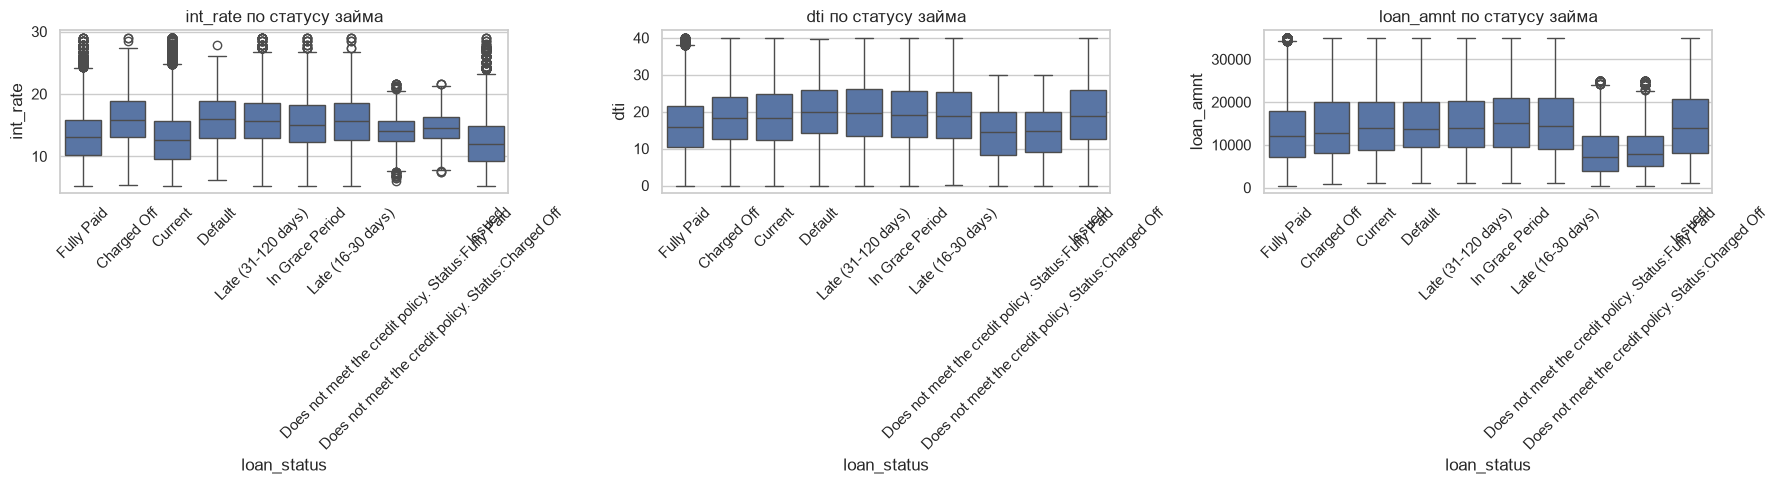

In [37]:
status_cols = ['int_rate', 'dti', 'loan_amnt']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, status_cols):
    sns.boxplot(data=df, x='loan_status', y=col, ax=ax)
    ax.set_title(f'{col} по статусу займа')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('boxplot_by_status.png', dpi=150)
plt.show()

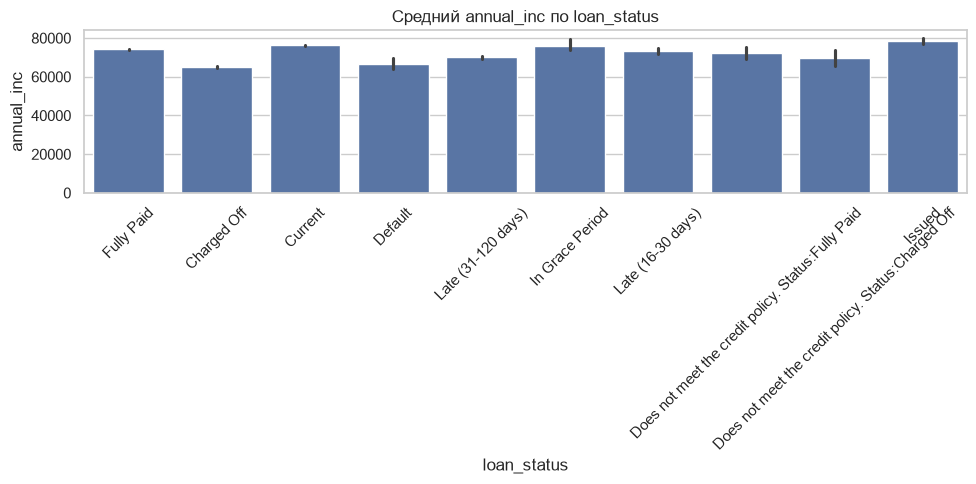

In [38]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='loan_status', y='annual_inc', estimator=np.mean)
plt.title('Средний annual_inc по loan_status')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('annual_inc_by_status.png', dpi=150)
plt.show()

             int_rate  loan_amnt  total_pymnt  total_acc
int_rate     1.000000   0.144827     0.170825  -0.038620
loan_amnt    0.144827   1.000000     0.475195   0.222657
total_pymnt  0.170825   0.475195     1.000000   0.109109
total_acc   -0.038620   0.222657     0.109109   1.000000


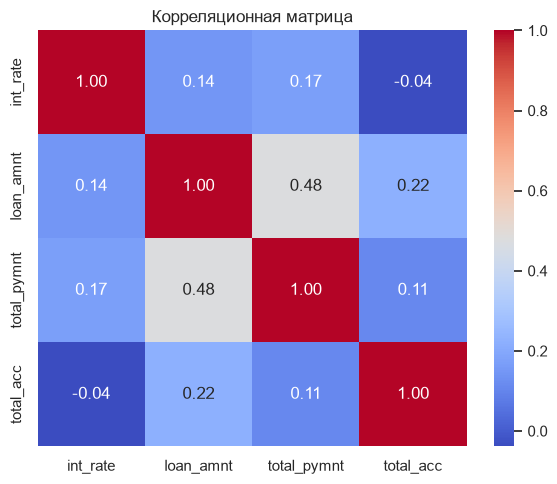

In [39]:
corr_cols = ['int_rate', 'loan_amnt', 'total_pymnt', 'total_acc']
corr_matrix = df[corr_cols].corr()
print(corr_matrix)

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Корреляционная матрица')
plt.tight_layout()
plt.savefig('corr_matrix.png', dpi=150)
plt.show()

Пара с наибольшей корреляцией: ('loan_amnt', 'total_pymnt') = 0.4751953903548779


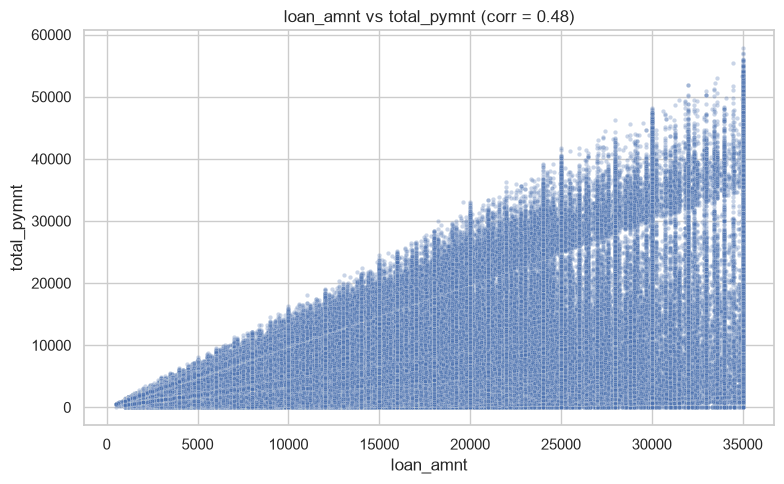

In [40]:
corr_unstacked = corr_matrix.unstack()
corr_unstacked = corr_unstacked[corr_unstacked.index.get_level_values(0)
                                != corr_unstacked.index.get_level_values(1)]
best_pair = corr_unstacked.abs().idxmax()
print('Пара с наибольшей корреляцией:', best_pair, '=', corr_unstacked[best_pair])

# График взаимосвязи
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=best_pair[0], y=best_pair[1], alpha=0.3, s=10)
plt.title(f'{best_pair[0]} vs {best_pair[1]} (corr = {corr_unstacked[best_pair]:.2f})')
plt.tight_layout()
plt.savefig('best_pair_scatter.png', dpi=150)
plt.show()